# Main question of this notebook

Do Entegris and TSMC merely move together, or does either stock’s movement precede the other’s?

In [76]:
%pip install yfinance
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [77]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm

In [78]:
tickers = ['TSM', 'ENTG', 'SPY']

prices = yf.download(
    tickers=tickers,
    start="2010-01-01",
    end="2022-12-31",
    interval="1d",
    auto_adjust=False,
    actions=True,
    keepna=True,
    repair=False,
)

prices.head()

[*********************100%***********************]  3 of 3 completed


Price      Adj Close                      Capital Gains Close              \
Ticker          ENTG        SPY       TSM           SPY  ENTG         SPY   
Date                                                                        
2010-01-04  5.158898  84.368996  7.199557           0.0  5.40  113.330002   
2010-01-05  5.044255  84.592331  7.168471           0.0  5.28  113.629997   
2010-01-06  4.958275  84.651909  7.143600           0.0  5.19  113.709999   
2010-01-07  4.996489  85.009201  6.907347           0.0  5.23  114.190002   
2010-01-08  4.996489  85.292099  6.901129           0.0  5.23  114.570000   

Price             Dividends            ...    Low  Open                     \
Ticker        TSM      ENTG  SPY  TSM  ...    TSM  ENTG         SPY    TSM   
Date                                   ...                                   
2010-01-04  11.58       0.0  0.0  0.0  ...  11.47  5.35  112.370003  11.49   
2010-01-05  11.53       0.0  0.0  0.0  ...  11.46  5.38  113.260002  11.60   
2010-01-06  11.49       0.0  0.0  0.0  ...  11.38  5.25  113.519997  11.56   
2010-01-07  11.11       0.0  0.0  0.0  ...  11.07  5.20  113.500000  11.41   
2010-01-08  11.10       0.0  0.0  0.0  ...  11.03  5.20  113.889999  11.14   

Price      Stock Splits             Volume                       
Ticker             ENTG  SPY  TSM     ENTG        SPY       TSM  
Date                                                             
2010-01-04          0.0  0.0  0.0   790500  118944600   8096400  
2010-01-05          0.0  0.0  0.0  1468700  111579900  14375900  
2010-01-06          0.0  0.0  0.0  2180300  116074400  13608400  
2010-01-07          0.0  0.0  0.0   802300  131091100  27346600  
2010-01-08          0.0  0.0  0.0   540800  126402800  16895300  

[5 rows x 25 columns]

In [79]:
adjusted_close = prices["Adj Close"].copy()

data_check = pd.DataFrame({
    "first_date": adjusted_close.apply(
        lambda column: column.first_valid_index()
    ),
    "last_date": adjusted_close.apply(
        lambda column: column.last_valid_index()
    ),
    "missing_prices": adjusted_close.isna().sum(),
})

display(data_check)

print("Dates in order:", adjusted_close.index.is_monotonic_increasing)
print("Duplicate dates:", adjusted_close.index.has_duplicates)

,first_date,last_date,missing_prices
Ticker,,,
ENTG,2010-01-04,2022-12-30,0
SPY,2010-01-04,2022-12-30,0
TSM,2010-01-04,2022-12-30,0


Dates in order: True
Duplicate dates: False


In [80]:
returns = adjusted_close.pct_change(fill_method=None).iloc[1:]
returns.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
ENTG,3271.0,0.001107,0.025879,-0.209681,-0.011916,0.001464,0.014176,0.202429
SPY,3271.0,0.000509,0.011094,-0.109424,-0.003731,0.000654,0.005748,0.090603
TSM,3271.0,0.000865,0.018314,-0.140341,-0.009198,0.000764,0.010560,0.126522


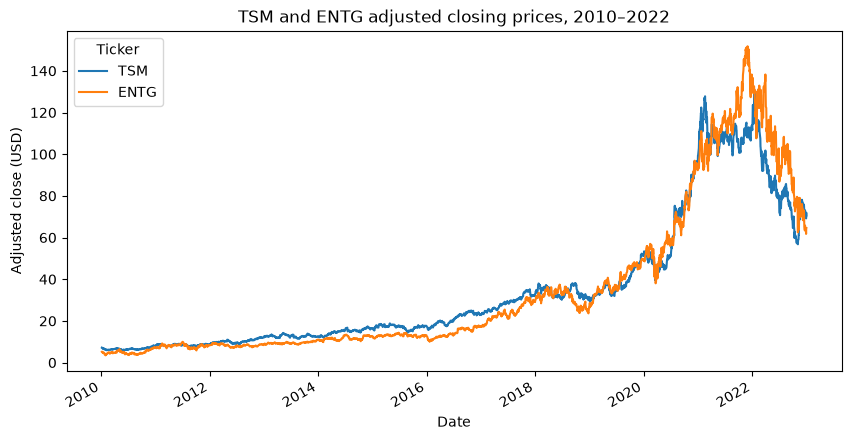

In [81]:
adjusted_close[["TSM", "ENTG"]].plot(
    figsize=(10, 5),
    title="TSM and ENTG adjusted closing prices, 2010–2022",
    xlabel="Date",
    ylabel="Adjusted close (USD)",
)

plt.show()

### Correlation Check 

In [82]:
returns_correlation_matrix = returns.corr()
returns_correlation_matrix

Ticker,ENTG,SPY,TSM
Ticker,,,
ENTG,1.000000,0.678634,0.558063
SPY,0.678634,1.000000,0.623230
TSM,0.558063,0.623230,1.000000


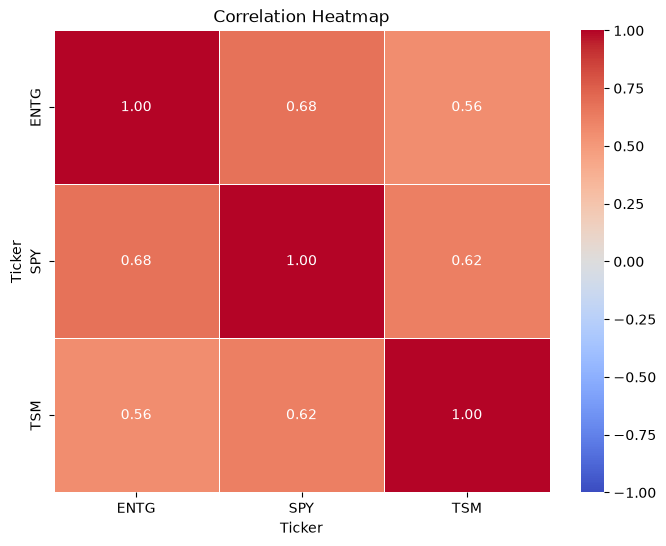

In [83]:
plt.figure(figsize=(8,6))
sns.heatmap(returns_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("Correlation Heatmap")
plt.show()

There is some promise, now we check whether the movement relationship is upstream/downstream. We check 1-day, 5-day, and 20-day lag correlation.

The returns correlation for the period 2010-2022 showed 0.56 for ENTG-TSM, SPY relationships are still higher - but this can just be general market movements.

Below we break down the period to 2010-2015 and then 2016-2022. 

In [84]:
returns_2010_2015 = returns.loc['2010':'2015']
returns_2016_2022 = returns.loc['2016':'2022']

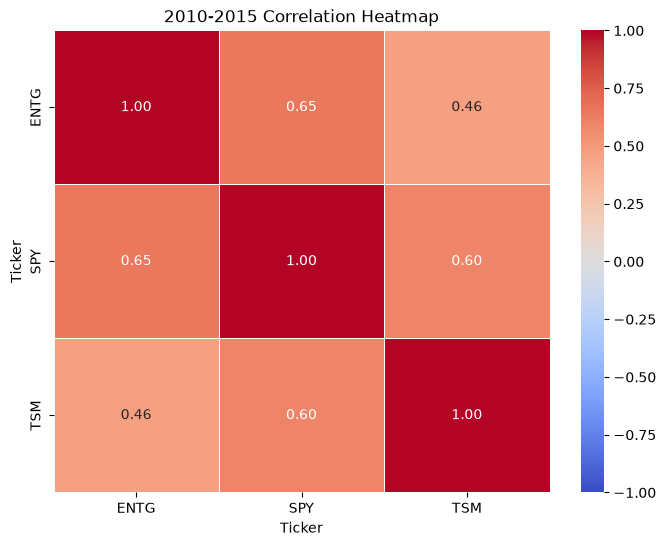

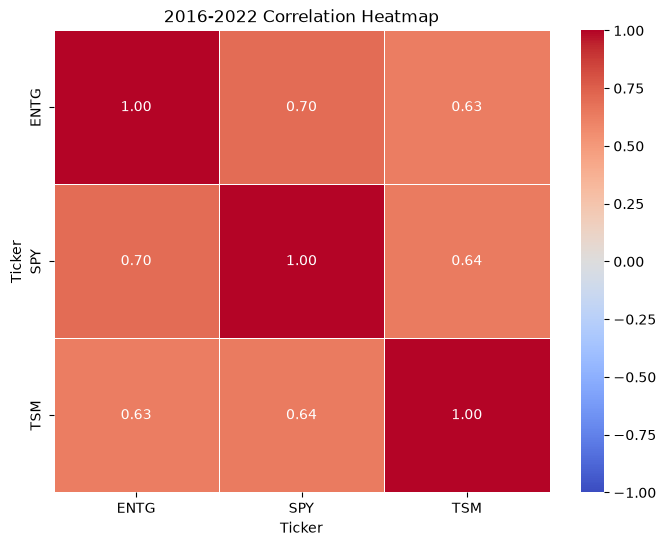

In [85]:
returns_2010_2015_correlation_matrix = returns_2010_2015.corr()
returns_2016_2022_correlation_matrix = returns_2016_2022.corr()

plt.figure(figsize=(8,6))
sns.heatmap(returns_2010_2015_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("2010-2015 Correlation Heatmap")
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(returns_2016_2022_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("2016-2022 Correlation Heatmap")
plt.show()

There is stronger correlation for the period 2016-2022. But still there is high correlation with the SPY, so regression will help to isolate beta. We do a residuals calculation for the entire period and then again for the separate 2010-2015 and then 2016-2022 separatly


In [86]:
residuals = {}

for ticker in ["TSM", "ENTG"]:
    regression_data = returns[[ticker, "SPY"]].dropna()
    y = regression_data[ticker]
    X = sm.add_constant(regression_data["SPY"])
    model = sm.OLS(y, X)
    result = model.fit()
    print(f"{ticker} - "f"Alpha: {result.params['const']:.6f}, "f"Beta: {result.params['SPY']:.4f}, "f"R-squared: {result.rsquared:.4f}")
    residuals[ticker] = result.resid


TSM - Alpha: 0.000341, Beta: 1.0288, R-squared: 0.3884
ENTG - Alpha: 0.000301, Beta: 1.5830, R-squared: 0.4605


In [87]:
residuals_df = pd.DataFrame(residuals)
residuals_df.head()

,TSM,ENTG
Date,,
2010-01-05,-0.007382,-0.026713
2010-01-06,-0.004535,-0.018461
2010-01-07,-0.037756,0.000725
2010-01-08,-0.004665,-0.005569
2010-01-11,-0.007183,-0.019720


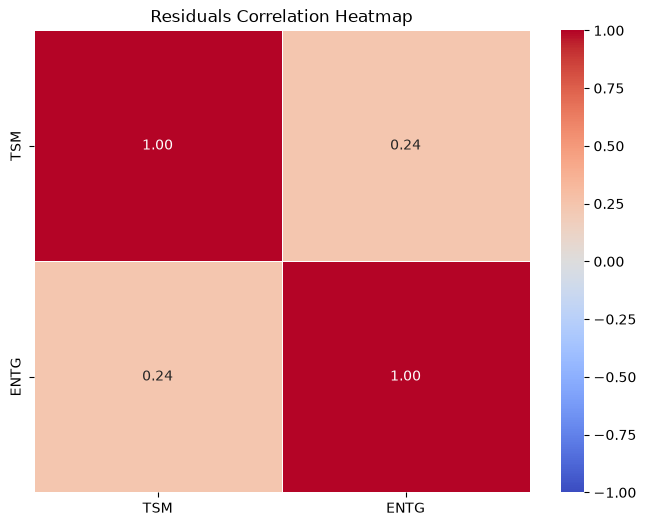

In [88]:
residuals_correlation_matrix = residuals_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(residuals_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)   
plt.title("Residuals Correlation Heatmap")
plt.show()


Controlling for SPY substantially reduces pairwise correlations, but all remain
positive. This suggests shared variation beyond the fitted SPY relationships. This correlation might be different accross the two periods so we check that now.    

In [89]:
residuals_2010_2015 = {}
residuals_2016_2022 = {}

for ticker in ["TSM", "ENTG"]:
    regression_data = returns_2010_2015[[ticker, "SPY"]].dropna()
    y = regression_data[ticker]
    X = sm.add_constant(regression_data["SPY"])
    model = sm.OLS(y, X)
    result = model.fit()
    print(f"{ticker} - "f"Alpha: {result.params['const']:.6f}, "f"Beta: {result.params['SPY']:.4f}, "f"R-squared: {result.rsquared:.4f}")
    residuals_2010_2015[ticker] = result.resid


for ticker in ["TSM", "ENTG"]:
    regression_data = returns_2016_2022[[ticker, "SPY"]].dropna()
    y = regression_data[ticker]
    X = sm.add_constant(regression_data["SPY"])
    model = sm.OLS(y, X)
    result = model.fit()
    print(f"{ticker} - "f"Alpha: {result.params['const']:.6f}, "f"Beta: {result.params['SPY']:.4f}, "f"R-squared: {result.rsquared:.4f}")
    residuals_2016_2022[ticker] = result.resid
    


TSM - Alpha: 0.000208, Beta: 0.9795, R-squared: 0.3580
ENTG - Alpha: 0.000048, Beta: 1.6794, R-squared: 0.4249
TSM - Alpha: 0.000463, Beta: 1.0580, R-squared: 0.4067
ENTG - Alpha: 0.000502, Beta: 1.5263, R-squared: 0.4919


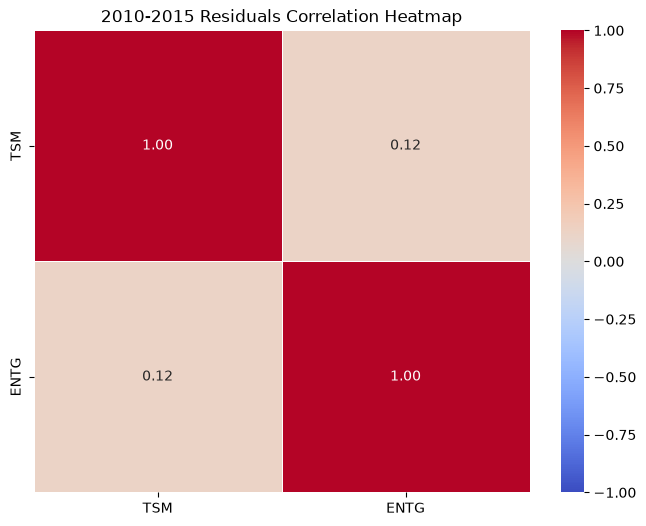

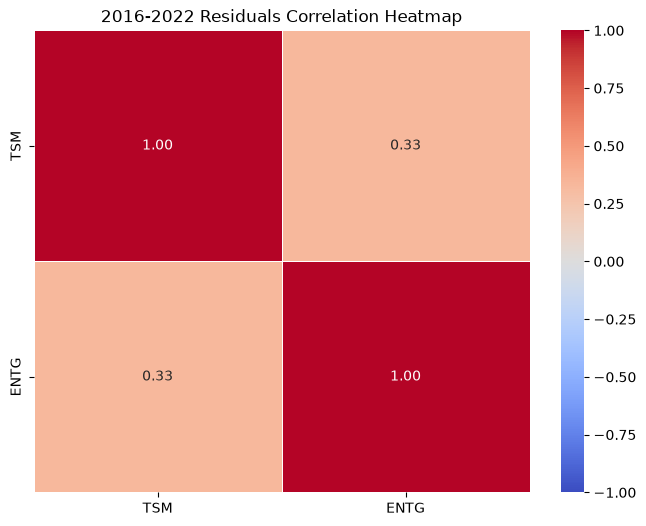

In [90]:
residuals_2010_2015_df = pd.DataFrame(residuals_2010_2015)
residuals_2016_2022_df = pd.DataFrame(residuals_2016_2022)

residuals_2010_2015_correlation_matrix = residuals_2010_2015_df.corr()
residuals_2016_2022_correlation_matrix = residuals_2016_2022_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(residuals_2010_2015_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("2010-2015 Residuals Correlation Heatmap")
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(residuals_2016_2022_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("2016-2022 Residuals Correlation Heatmap")
plt.show()

Now we check if there is a one-session lage. We do it both for ENTG leading TSM and then the reverse.

In [101]:
tsm_next = returns["TSM"].shift(-1).copy()
entg_next = returns["ENTG"].shift(-1).copy()

lagged_returns_entg_first = pd.DataFrame({
    "TSM_next": tsm_next,
    "ENTG": returns["ENTG"],
}).dropna()



lagged_returns_tsm_first = pd.DataFrame({
    "ENTG_next": entg_next,
    "TSM": returns["TSM"],
}).dropna()



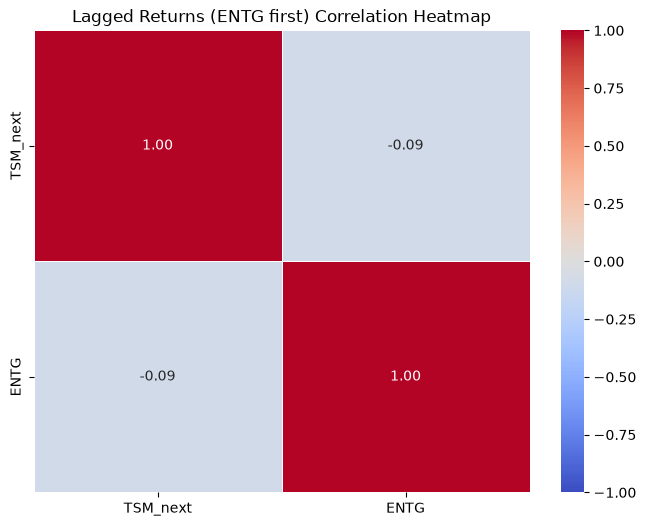

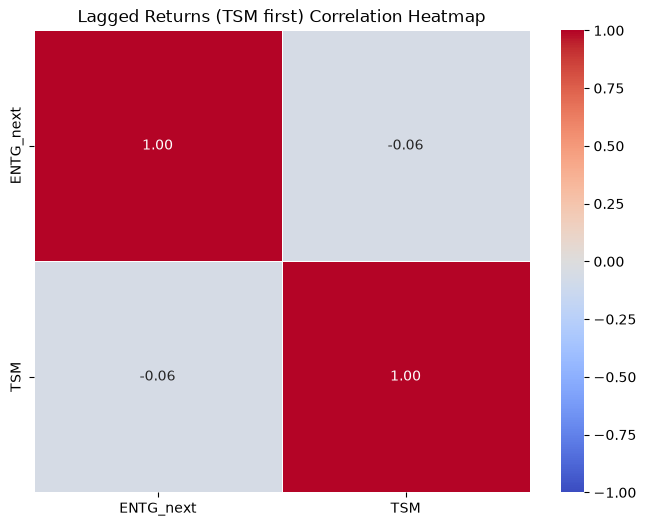

In [103]:
lagged_returns_entg_first_correlation_matrix = lagged_returns_entg_first.corr()
lagged_returns_tsm_first_correlation_matrix = lagged_returns_tsm_first.corr()

plt.figure(figsize=(8,6))
sns.heatmap(lagged_returns_entg_first_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("Lagged Returns (ENTG first) Correlation Heatmap")
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(lagged_returns_tsm_first_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title("Lagged Returns (TSM first) Correlation Heatmap")
plt.show()  

This not promising but now we check if we can see how we can predict TSM_next from todays ENTG, TSM, and SPY returns with an intercept.

In [104]:
regression_data = pd.DataFrame({
    "TSM_next": tsm_next,
    "ENTG": returns["ENTG"],
    "TSM": returns["TSM"],
    "SPY": returns["SPY"],
}).dropna()

y = regression_data["TSM_next"]

X_baseline = sm.add_constant(regression_data[["TSM", "SPY"]])
X_full = sm.add_constant(regression_data[["TSM", "SPY", "ENTG"]])

baseline_result = sm.OLS(y, X_baseline).fit()
full_result = sm.OLS(y, X_full).fit()

display(full_result.params.rename("Coefficient"))

print(f"Baseline R²: {baseline_result.rsquared:.6f}")
print(f"With ENTG R²: {full_result.rsquared:.6f}")
print(f"Observations: {int(full_result.nobs)}")

const    0.000983
TSM     -0.028586
SPY     -0.192371
ENTG     0.006412
Name: Coefficient, dtype: float64

Baseline R²: 0.016866
With ENTG R²: 0.016908
Observations: 3270


Knowing one-day info about ENTG does not cause significant improvements. 

In [106]:
split_data = regression_data.copy()


split_data["target_date"] = returns.index.to_series().shift(-1)

train_2016 = split_data.loc[
    split_data["target_date"] < "2016-01-01"
].copy()

validation_2016 = split_data.loc[
    (split_data["target_date"] >= "2016-01-01")
    & (split_data["target_date"] < "2017-01-01")
].copy()


assert (
    train_2016["target_date"].max() <= validation_2016.index.min()
), "Training includes an outcome unavailable at the first evaluation decision."

print("Training rows:", len(train_2016))
print("2016 evaluation rows:", len(validation_2016))

display(train_2016[["target_date"]].tail(2))
display(validation_2016[["target_date"]].head(2))

Training rows: 1508
2016 evaluation rows: 252


,target_date
Date,
2015-12-29,2015-12-30
2015-12-30,2015-12-31


,target_date
Date,
2015-12-31,2016-01-04
2016-01-04,2016-01-05
